# 🌸 Scikit-Learn Basics: Hands-On Examples & Guided Tutorial

Welcome to **Scikit-Learn Basics**! This notebook is an interactive, notebook-style version of `examples.py`, specifically designed for **study and learning**.

Every machine learning project revolves around a foundational workflow:
1. **Load and explore data**
2. **Split data into training and test sets**
3. **Preprocess and scale features**
4. **Train a model**
5. **Evaluate model performance**
6. **Cross-validate to assess stability**
7. **Assemble leak-proof Pipelines**

---

### 📋 Table of Contents
1. [Imports & Setup](#1.-Imports-&-Setup)
2. [Section 1: Dataset Exploration (The Iris Dataset)](#2.-Section-1:-Dataset-Exploration)
3. [Section 2: Train/Test Split & Stratification](#3.-Section-2:-Train/Test-Split-&-Stratification)
4. [Section 3: Feature Scaling (StandardScaler vs. MinMaxScaler)](#4.-Section-3:-Feature-Scaling)
5. [Section 4: Your First Model (K-Nearest Neighbors - KNN)](#5.-Section-4:-Your-First-Model:-K-Nearest-Neighbors)
6. [Section 5: Evaluation Metrics (Confusion Matrix & Classification Report)](#6.-Section-5:-Evaluation-Metrics)
7. [Section 6: Cross-Validation (K-Fold & Hyperparameter Tuning)](#7.-Section-6:-Cross-Validation)
8. [Section 7: Scikit-Learn Pipelines (Best Practice Workflow)](#8.-Section-7:-Pipelines:-The-Professional-Way)
9. [Key Takeaways & Summary](#9.-Key-Takeaways-&-Summary)


---
## 1. Imports & Setup

In modern Python and machine learning best practice:
- Keep all imports at the top of the notebook for clarity and dependency tracking.
- Set a **random seed / state** (`RANDOM_STATE = 42`) to ensure reproducible results across every run.
- Use `matplotlib` and `seaborn` to visualize patterns and model diagnostics.


In [1]:
# Core scientific computing and data analysis libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn dataset loader
from sklearn.datasets import load_iris

# Model selection and splitting
from sklearn.model_selection import train_test_split, cross_val_score

# Preprocessing and scaling
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Classifier algorithm
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Pipeline builder
from sklearn.pipeline import Pipeline

# Set global random state for reproducibility
RANDOM_STATE = 42

# Configure visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

print("Environment configured and libraries imported successfully!")


Environment configured and libraries imported successfully!


---
## 2. Section 1: Dataset Exploration

### What is the Iris Dataset?
The Iris dataset was introduced by Ronald Fisher in 1936 and is the classic benchmark dataset in pattern recognition and machine learning.

It contains:
- **150 observations** (samples)
- **4 numerical features**:
  - `sepal length (cm)`
  - `sepal width (cm)`
  - `petal length (cm)`
  - `petal width (cm)`
- **3 target classes** (flower species):
  - `0`: **Setosa**
  - `1`: **Versicolor**
  - `2`: **Virginica**

### Key Terminology
| Term | Notation | Description |
| :--- | :--- | :--- |
| **Samples ($n$)** | Rows ($150$) | Individual flowers measured |
| **Features ($p$)** | Columns ($4$) | Measurable properties of each flower |
| **Feature Matrix** | $X$ (uppercase) | 2D matrix of shape $(n, p)$ containing inputs |
| **Target Vector** | $y$ (lowercase) | 1D vector of length $n$ containing class labels |


In [2]:
# 1. Load the Iris dataset using scikit-learn
iris = load_iris()

# Inspect the dictionary-like Bunch object keys
print("Dataset Bunch keys:", list(iris.keys()))
print(f"Feature matrix (X) shape: {iris.data.shape}  --> (samples, features)")
print(f"Target vector  (y) shape: {iris.target.shape}  --> (labels,)")
print(f"Feature names : {iris.feature_names}")
print(f"Class names   : {list(iris.target_names)}")


Dataset Bunch keys: ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
Feature matrix (X) shape: (150, 4)  --> (samples, features)
Target vector  (y) shape: (150,)  --> (labels,)
Feature names : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names   : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### Converting to a pandas DataFrame for Inspection
While Scikit-Learn works natively with NumPy arrays, wrapping our data in a `pandas.DataFrame` provides human-readable column headers, summary statistics, and easier plotting.


In [3]:
# Convert feature matrix and targets into a convenient DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in iris.target]

# Preview the first 5 samples
print("--- First 5 Samples ---")
df.head()


--- First 5 Samples ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# Check class balance (distribution of species)
print("--- Class Distribution ---")
class_counts = df['species'].value_counts()
for species, count in class_counts.items():
    percentage = (count / len(df)) * 100
    print(f"  {species:12s}: {count:3d} samples ({percentage:.1f}%)")

print("\nObservation: The dataset is perfectly balanced (50 samples per class).")


--- Class Distribution ---
  setosa      :  50 samples (33.3%)
  versicolor  :  50 samples (33.3%)
  virginica   :  50 samples (33.3%)

Observation: The dataset is perfectly balanced (50 samples per class).


### Visualizing Feature Relationships
Before running any machine learning algorithm, **always visualize the data** to understand if the classes are linearly separable or if they overlap.


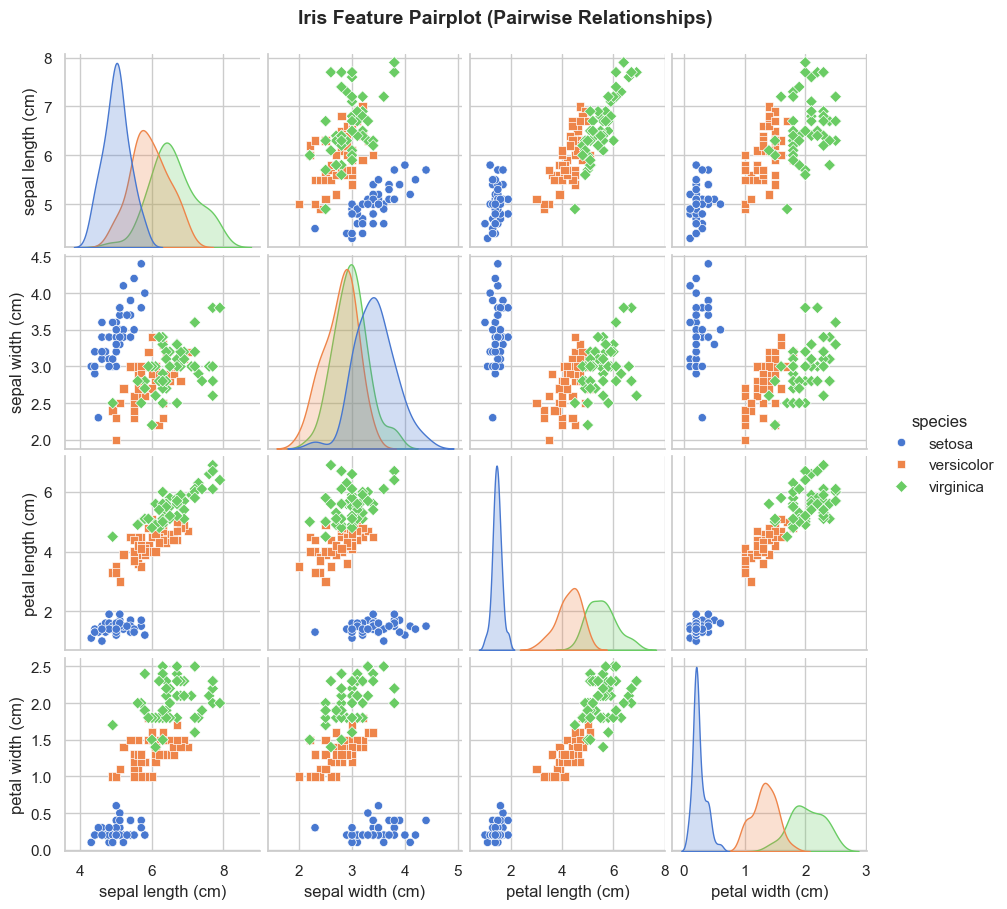

In [5]:
# Pairplot showing every feature combination color-coded by species
pairplot = sns.pairplot(df, hue="species", markers=["o", "s", "D"], height=2.2)
pairplot.fig.suptitle("Iris Feature Pairplot (Pairwise Relationships)", y=1.03, fontsize=14, weight="bold")
plt.show()


---
## 3. Section 2: Train/Test Split & Stratification

### Why Split Data?
If we train a model on all 150 samples and test on those same 150 samples, a model could simply memorize the inputs. This is known as **overfitting**.
To evaluate how well a model **generalizes to unseen data**, we partition the dataset into:
- **Training Set (typically 70% - 80%)**: Used by the algorithm to learn patterns.
- **Testing Set (typically 20% - 30%)**: Held-out data used strictly to measure performance.

### What is Stratification?
When splitting classification data, random sampling could accidentally assign all or most instances of a rare class to the training set or test set.
- Setting `stratify=y` guarantees that the train and test sets have the **exact same proportion of each class** as the original dataset.

### ⚠️ Warning: Preventing Data Leakage
**Data leakage** occurs when information from outside the training dataset (such as test set statistics) influences the model during training.
- **Rule**: Always perform your `train_test_split` **first**, before any normalization, scaling, or imputations.


In [6]:
# Extract feature matrix X and target vector y
X = iris.data
y = iris.target

# Split dataset: 80% train, 20% test with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,             # 20% for test set (30 samples)
    random_state=RANDOM_STATE,  # Fixed seed for reproducibility
    stratify=y                  # Maintain identical class proportions
)

print(f"Original dataset shape : X={X.shape}, y={y.shape}")
print(f"Training subset shape  : X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test subset shape      : X_test={X_test.shape}, y_test={y_test.shape}")


Original dataset shape : X=(150, 4), y=(150,)
Training subset shape  : X_train=(120, 4), y_train=(120,)
Test subset shape      : X_test=(30, 4), y_test=(30,)


In [7]:
# Verify that stratification preserved equal ratios across sets
print("--- Class Ratio Verification ---")
def format_class_ratios(subset_y, total_size):
    unique, counts = np.unique(subset_y, return_counts=True)
    return [f"{iris.target_names[u]}: {c/total_size:.1%}" for u, c in zip(unique, counts)]

print("Full dataset :", format_class_ratios(y, len(y)))
print("Train set    :", format_class_ratios(y_train, len(y_train)))
print("Test set     :", format_class_ratios(y_test, len(y_test)))


--- Class Ratio Verification ---
Full dataset : ['setosa: 33.3%', 'versicolor: 33.3%', 'virginica: 33.3%']
Train set    : ['setosa: 33.3%', 'versicolor: 33.3%', 'virginica: 33.3%']
Test set     : ['setosa: 33.3%', 'versicolor: 33.3%', 'virginica: 33.3%']


---
## 4. Section 3: Feature Scaling

### Why Feature Scaling Matters
Many machine learning algorithms (e.g., K-Nearest Neighbors, SVM, Logistic Regression with regularization, Gradient Descent) rely on calculating **Euclidean distances** or dot products between points.

If one feature has values from $0$ to $1000$ and another has values from $0$ to $1$, the distance calculation will be dominated almost entirely by the large-magnitude feature, rendering the smaller feature effectively ignored.

### StandardScaler vs. MinMaxScaler
| Scaler | Mathematical Formula | Output Properties | Best Suited For |
| :--- | :--- | :--- | :--- |
| **`StandardScaler`** | $z = \frac{x - \mu}{\sigma}$ | Mean $\mu = 0$, Std $\sigma = 1$ | Most general ML models (KNN, SVM, Linear models) |
| **`MinMaxScaler`** | $x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$ | Bounded in $[0, 1]$ | Algorithms requiring strictly positive values, Neural Networks, Image pixels |

### 📌 The Golden Rule of Preprocessing:
1. `scaler.fit_transform(X_train)`: Compute mean & std on **training data only**, then transform training data.
2. `scaler.transform(X_test)`: Apply the **learned training statistics** to transform the test data.
3. 🚫 **NEVER call `fit` or `fit_transform` on the test data!** That causes data leakage!


In [8]:
# Inspect statistics of features before scaling
print("--- Before Scaling (X_train) ---")
print(f"Mean per feature : {X_train.mean(axis=0).round(2)}")
print(f"Std per feature  : {X_train.std(axis=0).round(2)}")
print(f"Min / Max range  : [{X_train.min():.2f}, {X_train.max():.2f}]")


--- Before Scaling (X_train) ---
Mean per feature : [5.84 3.05 3.77 1.2 ]
Std per feature  : [0.84 0.45 1.76 0.76]
Min / Max range  : [0.10, 7.90]


In [9]:
# --- 1. StandardScaler Demo ---
std_scaler = StandardScaler()

# Fit parameters on X_train only, then transform X_train
X_train_std = std_scaler.fit_transform(X_train)

# Transform X_test using the parameters learned from X_train
X_test_std = std_scaler.transform(X_test)

print("--- After StandardScaler ---")
print(f"X_train_std mean per feature (should be ~0): {X_train_std.mean(axis=0).round(4)}")
print(f"X_train_std std per feature  (should be ~1): {X_train_std.std(axis=0).round(4)}")
print(f"X_test_std mean per feature  (unseen test) : {X_test_std.mean(axis=0).round(2)}")


--- After StandardScaler ---
X_train_std mean per feature (should be ~0): [-0. -0.  0.  0.]
X_train_std std per feature  (should be ~1): [1. 1. 1. 1.]
X_test_std mean per feature  (unseen test) : [ 0.01  0.1  -0.03 -0.04]


In [10]:
# --- 2. MinMaxScaler Demo ---
minmax_scaler = MinMaxScaler()

# Fit on train, transform train and test
X_train_mm = minmax_scaler.fit_transform(X_train)
X_test_mm = minmax_scaler.transform(X_test)

print("--- After MinMaxScaler ---")
print(f"X_train_mm range: [{X_train_mm.min():.2f}, {X_train_mm.max():.2f}]  --> strictly [0, 1]")
print(f"X_test_mm range : [{X_test_mm.min():.2f}, {X_test_mm.max():.2f}]")
print("Notice: Test set values can occasionally fall slightly below 0 or above 1")
print("because the scaler parameters (min/max) were learned from training data only!")


--- After MinMaxScaler ---
X_train_mm range: [0.00, 1.00]  --> strictly [0, 1]
X_test_mm range : [-0.02, 0.96]
Notice: Test set values can occasionally fall slightly below 0 or above 1
because the scaler parameters (min/max) were learned from training data only!


---
## 5. Section 4: Your First Model: K-Nearest Neighbors

### How K-Nearest Neighbors (KNN) Works
KNN is an intuitive, instance-based supervised learning algorithm:
1. **Store training data**: KNN does not compute explicit parameters (weights); it memorizes the training data.
2. **Calculate Distance**: When asked to classify a new point, it calculates the Euclidean distance between this point and all points in the training set.
3. **Find $K$ Closest Neighbors**: It selects the $K$ points with the smallest distances.
4. **Majority Vote**: The class with the most votes among those $K$ neighbors becomes the prediction.

### The Unified Scikit-Learn Estimator Pattern
Every model in scikit-learn follows this consistent 3-step interface:
```python
# 1. Instantiate the estimator with desired hyperparameters
model = KNeighborsClassifier(n_neighbors=5)

# 2. Fit (train) the model on training data
model.fit(X_train, y_train)

# 3. Predict labels on test / new data
y_pred = model.predict(X_test)

# 4. Score accuracy directly
score = model.score(X_test, y_test)
```


In [11]:
# Step 1: Instantiate the KNN classifier (choosing K=5 neighbors)
knn = KNeighborsClassifier(n_neighbors=5)

# Step 2: Fit on the scaled training data
knn.fit(X_train_std, y_train)

# Step 3: Predict class labels for test set
y_pred = knn.predict(X_test_std)

# Step 4: Evaluate test accuracy
test_accuracy = knn.score(X_test_std, y_test)
print(f"Model Training Complete!")
print(f"Test Accuracy: {test_accuracy:.2%}")


Model Training Complete!
Test Accuracy: 93.33%


In [12]:
# Compare first 10 actual labels vs predictions side-by-side
comparison_df = pd.DataFrame({
    'Actual Label': [iris.target_names[i] for i in y_test[:10]],
    'Predicted Label': [iris.target_names[i] for i in y_pred[:10]],
    'Correct?': [y_test[i] == y_pred[i] for i in range(10)]
})

comparison_df


,Actual Label,Predicted Label,Correct?
0,setosa,setosa,True
1,virginica,virginica,True
2,versicolor,versicolor,True
3,versicolor,versicolor,True
4,setosa,setosa,True
5,versicolor,versicolor,True
6,setosa,setosa,True
7,setosa,setosa,True
8,virginica,virginica,True
9,versicolor,versicolor,True


### Predicting on Brand-New, Unseen Flowers
Let's feed custom measurements to our model:
- `[5.1, 3.5, 1.4, 0.2]` (Small petal length & width $\rightarrow$ Setosa)
- `[6.7, 3.0, 5.2, 2.3]` (Large petal length & width $\rightarrow$ Virginica)
- `[5.9, 3.0, 4.2, 1.5]` (Medium dimensions $\rightarrow$ Versicolor)


In [13]:
# Define new sample observations
new_samples = np.array([
    [5.1, 3.5, 1.4, 0.2],
    [6.7, 3.0, 5.2, 2.3],
    [5.9, 3.0, 4.2, 1.5]
])

# CRITICAL: New samples MUST be scaled using the existing fitted scaler!
new_samples_scaled = std_scaler.transform(new_samples)

# Generate predictions and class probability distributions
sample_predictions = knn.predict(new_samples_scaled)
sample_probabilities = knn.predict_proba(new_samples_scaled)

print("--- Predictions on New Samples ---")
for i, sample in enumerate(new_samples):
    predicted_species = iris.target_names[sample_predictions[i]]
    probs = {iris.target_names[j]: f"{prob:.1%}" for j, prob in enumerate(sample_probabilities[i])}
    print(f"Sample {sample} -> Predicted: {predicted_species:10s} | Probabilities: {probs}")


--- Predictions on New Samples ---
Sample [5.1 3.5 1.4 0.2] -> Predicted: setosa     | Probabilities: {np.str_('setosa'): '100.0%', np.str_('versicolor'): '0.0%', np.str_('virginica'): '0.0%'}
Sample [6.7 3.  5.2 2.3] -> Predicted: virginica  | Probabilities: {np.str_('setosa'): '0.0%', np.str_('versicolor'): '0.0%', np.str_('virginica'): '100.0%'}
Sample [5.9 3.  4.2 1.5] -> Predicted: versicolor | Probabilities: {np.str_('setosa'): '0.0%', np.str_('versicolor'): '100.0%', np.str_('virginica'): '0.0%'}


---
## 6. Section 5: Evaluation Metrics

### Why Accuracy Is Not Always Enough
On balanced datasets like Iris, **Accuracy** gives a reasonable initial check:
$$\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}}$$

However, in real-world scenarios (e.g. fraud detection, medical diagnoses with 99% healthy patients):
- A dumb classifier that always predicts "healthy" gets 99% accuracy, yet misses 100% of sick patients!
- Therefore, we analyze **Precision**, **Recall**, **F1-Score**, and the **Confusion Matrix**.

### Key Metric Definitions
| Metric | Formula | Practical Meaning |
| :--- | :--- | :--- |
| **Precision** | $\frac{TP}{TP + FP}$ | "Of all samples predicted as positive, how many were actually positive?" (Minimizes false alarms) |
| **Recall (Sensitivity)** | $\frac{TP}{TP + FN}$ | "Of all actual positive samples, how many did the model detect?" (Minimizes missed cases) |
| **F1-Score** | $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ | Harmonic mean balancing Precision and Recall |


In [14]:
# 1. Compute accuracy score
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {acc:.2%}\n")

# 2. Detailed Classification Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Accuracy Score: 93.33%

--- Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



### The Confusion Matrix
A **Confusion Matrix** visualizes prediction errors:
- **Rows** represent the **True (Actual) Classes**.
- **Columns** represent the **Predicted Classes**.
- Values on the **diagonal** represent correct classifications ($TP$ and $TN$).
- Off-diagonal elements represent misclassifications ($FP$ and $FN$).


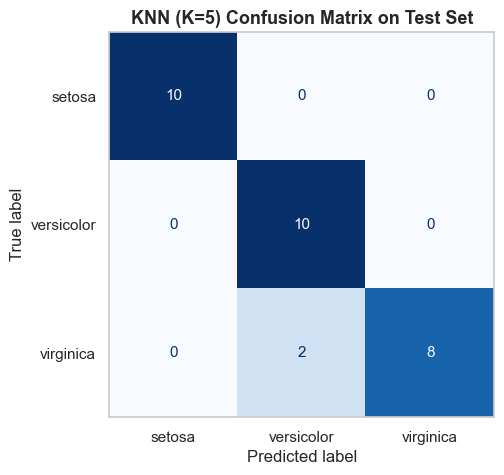

Confusion Matrix Array:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


In [15]:
# Compute and plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

ax.set_title("KNN (K=5) Confusion Matrix on Test Set", fontsize=13, weight="bold")
plt.grid(False) # Turn off grid lines for clean matrix display
plt.show()

print("Confusion Matrix Array:")
print(cm)


---
## 7. Section 6: Cross-Validation

### Why a Single Split Isn't Enough
A single train/test split has high variance:
- Depending on the `random_state`, you might get an unusually "easy" test set or an unusually "hard" test set.
- **K-Fold Cross-Validation** solves this by splitting the training data into $K$ equal subsets (folds).
- The model is trained on $K-1$ folds and tested on the remaining fold.
- This process repeats $K$ times so every fold serves as the test set once.
- The final score is reported as $\text{Mean} \pm \text{Standard Deviation}$.

```
Fold 1: [ Test  | Train | Train | Train | Train ]  --> Score 1
Fold 2: [ Train | Test  | Train | Train | Train ]  --> Score 2
Fold 3: [ Train | Train | Test  | Train | Train ]  --> Score 3
Fold 4: [ Train | Train | Train | Test  | Train ]  --> Score 4
Fold 5: [ Train | Train | Train | Train | Test  ]  --> Score 5
Final Performance = Mean(Scores) ± Std(Scores)
```


In [16]:
# We scale the full feature set for demonstration of standard cross-validation
full_scaler = StandardScaler()
X_scaled = full_scaler.fit_transform(X)

# 5-fold cross validation on KNN with K=5
cv_model = KNeighborsClassifier(n_neighbors=5)
cv_scores = cross_val_score(cv_model, X_scaled, y, cv=5, scoring='accuracy')

print("--- 5-Fold Cross-Validation Results ---")
print(f"Individual Fold Scores : {cv_scores.round(4)}")
print(f"Mean CV Accuracy       : {cv_scores.mean():.2%}")
print(f"Standard Deviation (±) : {cv_scores.std():.2%}")
print(f"Interpretation: Model performance is expected to be {cv_scores.mean():.2%} ± {cv_scores.std():.2%}.")


--- 5-Fold Cross-Validation Results ---
Individual Fold Scores : [0.9667 0.9667 0.9333 0.9333 1.    ]
Mean CV Accuracy       : 96.00%
Standard Deviation (±) : 2.49%
Interpretation: Model performance is expected to be 96.00% ± 2.49%.


### Hyperparameter Tuning: Choosing the Optimal $K$
What is the best number of neighbors $K$?
- If $K=1$: The model memorizes noise and outliers (**overfitting**).
- If $K$ is too large (e.g., $K=50$): Decision boundaries become overly smooth and lose class distinction (**underfitting**).

Let's test odd values of $K$ from $1$ to $25$ using 5-Fold Cross-Validation to find the optimal sweet spot!


Optimal K = 5 with Mean CV Accuracy = 96.00%


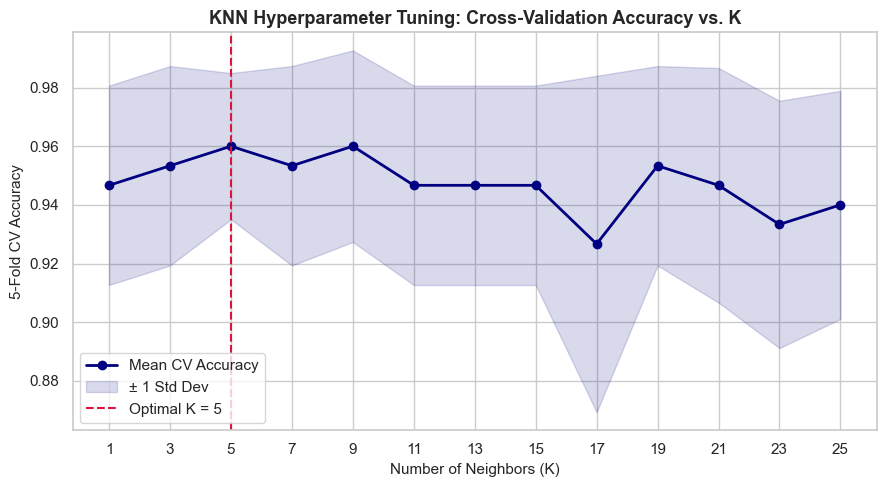

In [17]:
k_range = range(1, 26, 2) # Odd numbers to prevent ties in majority voting
k_means = []
k_stds = []

for k in k_range:
    test_knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(test_knn, X_scaled, y, cv=5, scoring='accuracy')
    k_means.append(scores.mean())
    k_stds.append(scores.std())

k_means = np.array(k_means)
k_stds = np.array(k_stds)

best_idx = np.argmax(k_means)
best_k = list(k_range)[best_idx]
print(f"Optimal K = {best_k} with Mean CV Accuracy = {k_means[best_idx]:.2%}")

# Plot Validation Curve for Hyperparameter K
plt.figure(figsize=(9, 5))
plt.plot(k_range, k_means, 'o-', color='navy', lw=2, label='Mean CV Accuracy')
plt.fill_between(k_range, k_means - k_stds, k_means + k_stds, alpha=0.15, color='navy', label='± 1 Std Dev')
plt.axvline(best_k, color='crimson', linestyle='--', label=f'Optimal K = {best_k}')
plt.title("KNN Hyperparameter Tuning: Cross-Validation Accuracy vs. K", fontsize=13, weight="bold")
plt.xlabel("Number of Neighbors (K)", fontsize=11)
plt.ylabel("5-Fold CV Accuracy", fontsize=11)
plt.xticks(list(k_range))
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()


---
## 8. Section 7: Pipelines: The Professional Way

### The Problem With Manual Preprocessing
In standard scripts, doing:
1. `scaler.fit_transform(X_train)`
2. `scaler.transform(X_test)`
3. `model.fit(X_train_scaled, y_train)`
4. `model.predict(X_test_scaled)`

is error-prone:
- If you run cross-validation manually on pre-scaled data, the scaler saw information from the test folds during its calculation $\rightarrow$ **Data Leakage**!
- If you deploy your model, you must remember to manually save and invoke both the scaler and the classifier in exact sequence.

### The Solution: Scikit-Learn `Pipeline`
A **`Pipeline`** bundles data transformations and an estimator into a single, cohesive object:
- **Leak-free Cross-Validation**: Inside each fold, the scaler is fit ONLY on the training fold, then applied to the validation fold.
- **Clean Interface**: `pipeline.fit()`, `pipeline.predict()`, `pipeline.score()` handles all transformations automatically under the hood.


In [18]:
# Build an end-to-end Pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),                       # Step 1: Feature scaling
    ('classifier', KNeighborsClassifier(n_neighbors=best_k))  # Step 2: Optimal KNN classifier
])

print("Pipeline Architecture:")
print(pipe)


Pipeline Architecture:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier())])


In [19]:
# 1. Leak-Free Cross-Validation on the Pipeline
pipe_cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
print(f"Pipeline 5-Fold CV Accuracy: {pipe_cv_scores.mean():.2%} ± {pipe_cv_scores.std():.2%}")

# 2. Train the entire pipeline on the full training set
pipe.fit(X_train, y_train)

# 3. Evaluate directly on raw unseen test set (Pipeline handles scaling automatically!)
train_acc = pipe.score(X_train, y_train)
test_acc = pipe.score(X_test, y_test)

print(f"\nPipeline Train Accuracy : {train_acc:.2%}")
print(f"Pipeline Test Accuracy  : {test_acc:.2%}")
print(f"Train-Test Difference   : {abs(train_acc - test_acc):.2%} (Indicates healthy generalization)")


Pipeline 5-Fold CV Accuracy: 96.67% ± 3.12%

Pipeline Train Accuracy : 97.50%
Pipeline Test Accuracy  : 93.33%
Train-Test Difference   : 4.17% (Indicates healthy generalization)


In [20]:
# 4. Predict on raw new flowers with zero manual scaling!
new_flowers_raw = np.array([
    [5.1, 3.5, 1.4, 0.2],  # Expected Setosa
    [6.7, 3.0, 5.2, 2.3],  # Expected Virginica
    [5.9, 3.0, 4.2, 1.5],  # Expected Versicolor
])

# The pipeline automatically transforms inputs using its fitted StandardScaler
pipeline_predictions = pipe.predict(new_flowers_raw)

print("--- Pipeline End-to-End Predictions ---")
for flower, pred_idx in zip(new_flowers_raw, pipeline_predictions):
    predicted_species = iris.target_names[pred_idx]
    print(f"Raw measurement {flower} --> Predicted Species: {predicted_species}")


--- Pipeline End-to-End Predictions ---
Raw measurement [5.1 3.5 1.4 0.2] --> Predicted Species: setosa
Raw measurement [6.7 3.  5.2 2.3] --> Predicted Species: virginica
Raw measurement [5.9 3.  4.2 1.5] --> Predicted Species: versicolor


In [21]:
# Inspecting Pipeline components and named steps
print("--- Pipeline Steps Inspection ---")
for step_name, step_obj in pipe.named_steps.items():
    print(f"Step '{step_name}': {step_obj.__class__.__name__}")

# Access scaler properties learned during pipeline fitting
print(f"\nLearned feature means from scaler step:\n{pipe.named_steps['scaler'].mean_.round(3)}")


--- Pipeline Steps Inspection ---
Step 'scaler': StandardScaler
Step 'classifier': KNeighborsClassifier

Learned feature means from scaler step:
[5.842 3.048 3.77  1.205]


---
## 9. Key Takeaways & Summary

### Summary of Machine Learning Fundamentals
1. **The Consistent Scikit-Learn API**:
   - `.fit(X, y)`: Trains the estimator on data.
   - `.predict(X)`: Generates predictions on new data.
   - `.score(X, y)`: Calculates the default evaluation metric (accuracy for classification, $R^2$ for regression).
   - `.transform(X)` / `.fit_transform(X)`: Used for preprocessing steps like scalers and encoders.

2. **Always Split First**:
   - Partition data into training and testing sets before any transformations to prevent data leakage.
   - Use `stratify=y` for classification to maintain class proportions.

3. **Feature Scaling Rules**:
   - Essential for distance-based models (KNN, SVM) and gradient-based models.
   - Fit scalers **only** on training data: `fit_transform(X_train)`, then `transform(X_test)`.

4. **Comprehensive Evaluation**:
   - Look beyond accuracy: use Confusion Matrices, Precision, Recall, and F1-Scores.

5. **Cross-Validation**:
   - Yields reliable estimates of model generalization across multiple data splits.

6. **Scikit-Learn Pipelines**:
   - The gold standard for modern ML code: chains preprocessing and models, eliminates leakage, and simplifies inference.

---
### Next Steps in Your Learning Journey
- Try other algorithms such as **Logistic Regression**, **Decision Trees**, and **Random Forests**.
- Explore other datasets in `sklearn.datasets` such as `load_wine()` and `load_breast_cancer()`.
- Check out `exercises.py` and `project.py` in this directory to practice what you learned!
